**DATA MINING TECHNIQUES**

**Anomaly Detection Analysis - Philippine Industrial Withdrawal Dataset**

Saving philippine_industrial_withdrawal_clean.csv to philippine_industrial_withdrawal_clean.csv
Successfully uploaded: philippine_industrial_withdrawal_clean.csv

Dataset Preview:


,entity,code,year,industrial_water_withdrawal,withdrawal_mcm
0,Philippines,PHL,1995,2296000004,2296.000004
1,Philippines,PHL,1996,2418200016,2418.200016
2,Philippines,PHL,1997,2540400028,2540.400028
3,Philippines,PHL,1998,2662600040,2662.600040
4,Philippines,PHL,1999,2784800053,2784.800053



========== IQR RESULTS ==========
Q1: 4424.00 MCM
Q3: 9931.00 MCM
IQR: 5507.00 MCM
Lower Bound: -3836.50 MCM
Upper Bound: 18191.50 MCM

========== POTENTIAL ANOMALIES ==========
No potential anomalies detected.

Total Potential Anomalies: 0


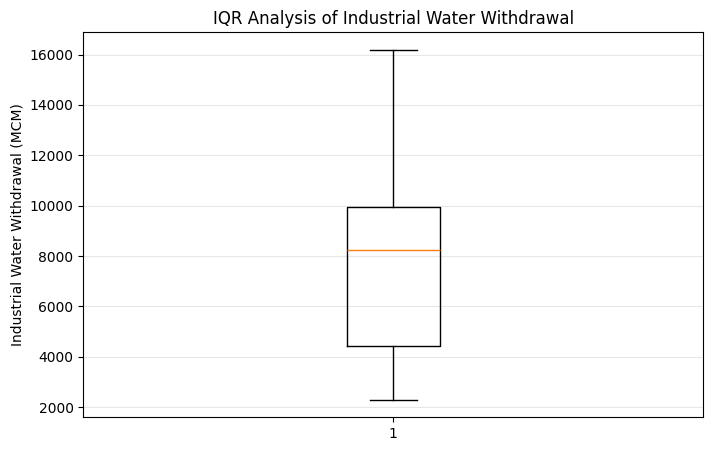

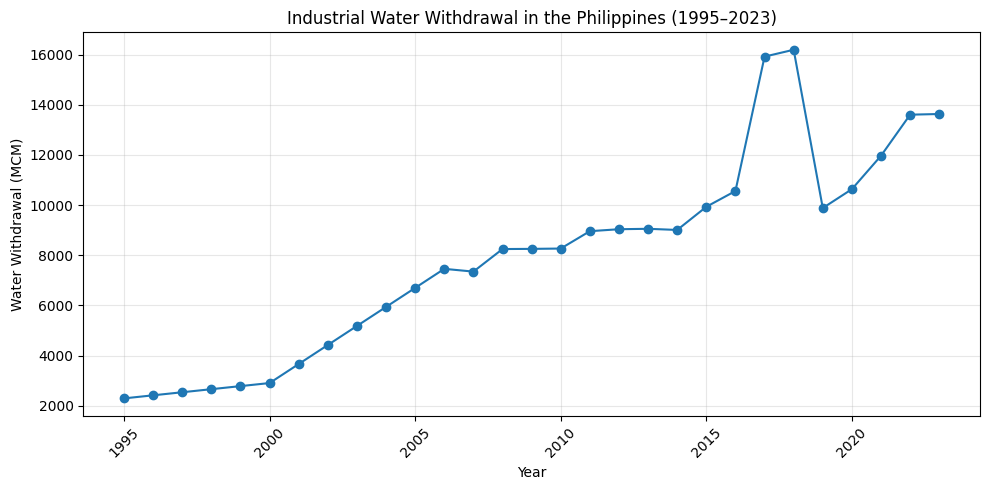

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files
import io

# =====================================
# 1. UPLOAD CSV FILE
# =====================================

uploaded = files.upload()

# Read the uploaded CSV file
file_name = next(iter(uploaded))
df = pd.read_csv(io.BytesIO(uploaded[file_name]))

print("Successfully uploaded:", file_name)
print("\nDataset Preview:")
display(df.head())

# =====================================
# 2. SELECT THE INDICATOR
# =====================================

data = df["withdrawal_mcm"].dropna()

# =====================================
# 3. CALCULATE IQR
# =====================================

Q1 = data.quantile(0.25)
Q3 = data.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

# =====================================
# 4. IDENTIFY POTENTIAL ANOMALIES
# =====================================

df["Potential_Anomaly"] = (
    (df["withdrawal_mcm"] < lower_bound) |
    (df["withdrawal_mcm"] > upper_bound)
)

# =====================================
# 5. DISPLAY RESULTS
# =====================================

print("\n========== IQR RESULTS ==========")
print(f"Q1: {Q1:.2f} MCM")
print(f"Q3: {Q3:.2f} MCM")
print(f"IQR: {IQR:.2f} MCM")
print(f"Lower Bound: {lower_bound:.2f} MCM")
print(f"Upper Bound: {upper_bound:.2f} MCM")

anomalies = df.loc[
    df["Potential_Anomaly"],
    ["year", "withdrawal_mcm"]
]

print("\n========== POTENTIAL ANOMALIES ==========")

if anomalies.empty:
    print("No potential anomalies detected.")
else:
    display(anomalies)

print("\nTotal Potential Anomalies:",
      len(anomalies))

# =====================================
# 6. BOXPLOT VISUALIZATION
# =====================================

plt.figure(figsize=(8, 5))

plt.boxplot(data)

plt.title("IQR Analysis of Industrial Water Withdrawal")
plt.ylabel("Industrial Water Withdrawal (MCM)")
plt.grid(axis="y", alpha=0.3)

plt.show()

# =====================================
# 7. YEARLY WITHDRAWAL VISUALIZATION
# =====================================

plt.figure(figsize=(10, 5))

plt.plot(
    df["year"],
    df["withdrawal_mcm"],
    marker="o"
)

plt.title("Industrial Water Withdrawal in the Philippines (1995–2023)")
plt.xlabel("Year")
plt.ylabel("Water Withdrawal (MCM)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


**INTERPRETATION:**

> The IQR analysis identified no potential anomalies in Philippine industrial water withdrawal from 1995 to 2023. All 29 observations were within the calculated lower and upper boundaries. However, the yearly trend showed a considerable increase in industrial water withdrawal, particularly around 2017 and 2018, followed by a decline in 2019. Although these observations were not classified as statistical outliers, they are notable changes that may require further investigation.



**Anomaly Detection Analysis - Water Use Efficiency Dataset**

Saving water_use_efficiency_clean.csv to water_use_efficiency_clean (1).csv
Successfully uploaded: water_use_efficiency_clean (1).csv

Dataset Preview:


,year,gva_agriculture,gva_industry,gva_services,water_used_agriculture,water_used_industry,water_used_services,wue_agriculture,wue_industry,wue_services,wue_overall,change_in_wue
0,2016,9.691714e+05,4776266,9614325,67916.478579,10629.940687,7752.318127,14.270048,449.321980,1256.645108,177.983628,0.067436
1,2017,1.014180e+06,5115225,10317618,67942.361844,15915.530000,8062.310000,14.927067,321.398345,1330.907456,178.927187,0.005301
2,2018,1.038671e+06,5490597,11011975,67944.549454,16188.805031,8148.932498,15.287042,339.160116,1365.858544,190.082450,0.062345
3,2019,1.069192e+06,5791358,11807538,67809.224838,9880.981984,8304.307156,15.767645,586.111584,1421.857089,217.084637,0.142055
4,2020,1.058773e+06,5015356,10742097,67851.090050,10633.614978,8992.564147,15.604357,471.651081,1194.553280,192.235375,-0.114468



========== IQR RESULTS ==========
Q1: 366.01
Q3: 452.39
IQR: 86.39
Lower Bound: 236.43
Upper Bound: 581.97

========== POTENTIAL ANOMALIES ==========


,year,wue_industry
3,2019,586.111584



Total Potential Anomalies: 1


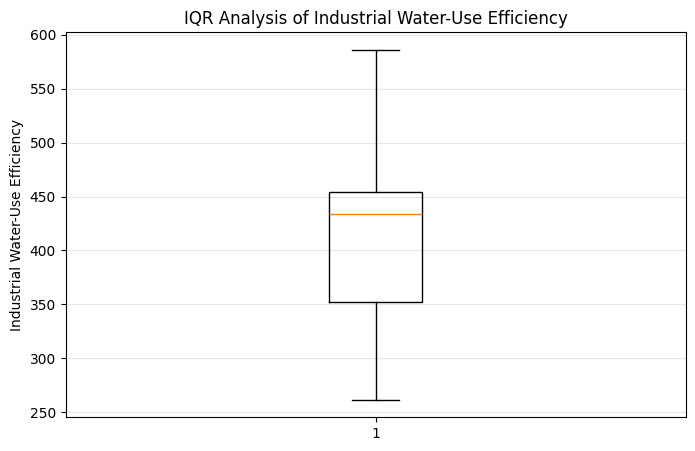

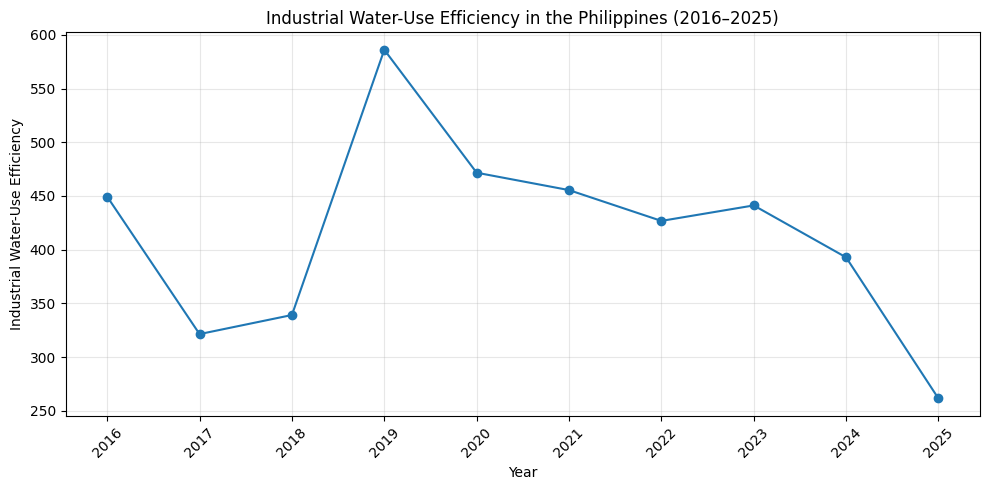

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files
import io

# =====================================
# 1. UPLOAD CSV FILE
# =====================================

uploaded = files.upload()

file_name = next(iter(uploaded))
df = pd.read_csv(io.BytesIO(uploaded[file_name]))

print("Successfully uploaded:", file_name)
print("\nDataset Preview:")
display(df.head())

# =====================================
# 2. SELECT INDUSTRIAL WUE
# =====================================

data = df["wue_industry"].dropna()


# =====================================
# 3. CALCULATE IQR
# =====================================

Q1 = data.quantile(0.25, interpolation="midpoint")
Q3 = data.quantile(0.75, interpolation="midpoint")

IQR = Q3 - Q1

lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)


# =====================================
# 4. IDENTIFY POTENTIAL ANOMALIES
# =====================================

df["Potential_Anomaly"] = (
    (df["wue_industry"] < lower_bound) |
    (df["wue_industry"] > upper_bound)
)

# =====================================
# 5. DISPLAY RESULTS
# =====================================

print("\n========== IQR RESULTS ==========")
print(f"Q1: {Q1:.2f}")
print(f"Q3: {Q3:.2f}")
print(f"IQR: {IQR:.2f}")
print(f"Lower Bound: {lower_bound:.2f}")
print(f"Upper Bound: {upper_bound:.2f}")

anomalies = df.loc[
    df["Potential_Anomaly"],
    ["year", "wue_industry"]
]

print("\n========== POTENTIAL ANOMALIES ==========")

if anomalies.empty:
    print("No potential anomalies detected.")
else:
    display(anomalies)

print("\nTotal Potential Anomalies:",
      len(anomalies))

# =====================================
# 6. BOXPLOT VISUALIZATION
# =====================================

plt.figure(figsize=(8, 5))

plt.boxplot(data)

plt.title("IQR Analysis of Industrial Water-Use Efficiency")
plt.ylabel("Industrial Water-Use Efficiency")
plt.grid(axis="y", alpha=0.3)

plt.show()

# =====================================
# 7. YEARLY TREND VISUALIZATION
# =====================================

plt.figure(figsize=(10, 5))

plt.plot(
    df["year"],
    df["wue_industry"],
    marker="o"
)

plt.title("Industrial Water-Use Efficiency in the Philippines (2016–2025)")
plt.xlabel("Year")
plt.ylabel("Industrial Water-Use Efficiency")
plt.xticks(df["year"], rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


**Interpretation:**

> The IQR analysis identified one potential statistical anomaly in 2019, when industrial water-use efficiency reached 586.11 PHP/m³. This value exceeded the calculated upper boundary of 581.97 PHP/m³, indicating that it was unusually high compared with the other annual observations.The yearly trend also showed fluctuations in industrial water-use efficiency, with the lowest value recorded in 2025 at approximately 261.47 PHP/m³. The results suggest that the economic value generated relative to industrial water use varied considerably during the observed period. However, the analysis alone cannot determine the reasons behind these changes.

The Anomaly Detection analysis revealed different patterns in Philippine industrial water withdrawal and water-use efficiency. The industrial water withdrawal dataset did not contain any potential statistical anomalies based on the IQR method, while the industrial water-use efficiency dataset identified one potential anomaly in 2019. These findings suggest that although industrial water withdrawal showed considerable changes over time, its annual values remained within the calculated statistical boundaries. Meanwhile, the unusually high industrial water-use efficiency in 2019 indicates a notable observation that may require further investigation.

Overall, the results demonstrate the usefulness of Anomaly Detection in identifying unusual observations in water-related indicators. However, statistical anomalies do not automatically represent errors or actual water-resource problems. Other economic, industrial, and environmental factors should be considered before drawing conclusions about the causes of these patterns.

**Trend Analysis - Historical Trends across the Available Years**

Saving annual_master_dataset.csv to annual_master_dataset (2).csv
Saving common_period_dataset.csv to common_period_dataset (2).csv
Both datasets uploaded successfully!

Annual Master Dataset:


,year,total_supply,total_use,owid_industrial_withdrawal_mcm,water_used_industry,wue_industry,wue_overall,water_withdrawal_mcm,water_stress
0,1995,NaN,NaN,2296.000004,NaN,NaN,NaN,NaN,NaN
1,1996,NaN,NaN,2418.200016,NaN,NaN,NaN,NaN,NaN
2,1997,NaN,NaN,2540.400028,NaN,NaN,NaN,NaN,NaN
3,1998,NaN,NaN,2662.600040,NaN,NaN,NaN,NaN,NaN
4,1999,NaN,NaN,2784.800053,NaN,NaN,NaN,NaN,NaN



Common Period Dataset:


,year,total_supply,total_use,owid_industrial_withdrawal_mcm,water_used_industry,wue_industry,wue_overall,water_withdrawal_mcm,water_stress
0,2016,603807.0,603807.0,10560.000420,10629.940687,449.321980,177.983628,86298.737394,0.263830
1,2017,635746.0,635746.0,15915.530205,15915.530000,321.398345,178.927187,91920.201844,0.281016
2,2018,643195.0,643195.0,16188.804626,16188.805031,339.160116,190.082450,92282.286983,0.282123
3,2019,650108.0,650108.0,9880.982399,9880.981984,586.111584,217.084637,85994.513979,0.262900
4,2020,654859.0,654859.0,10633.614540,10633.614978,471.651081,192.235375,87477.269175,0.267433


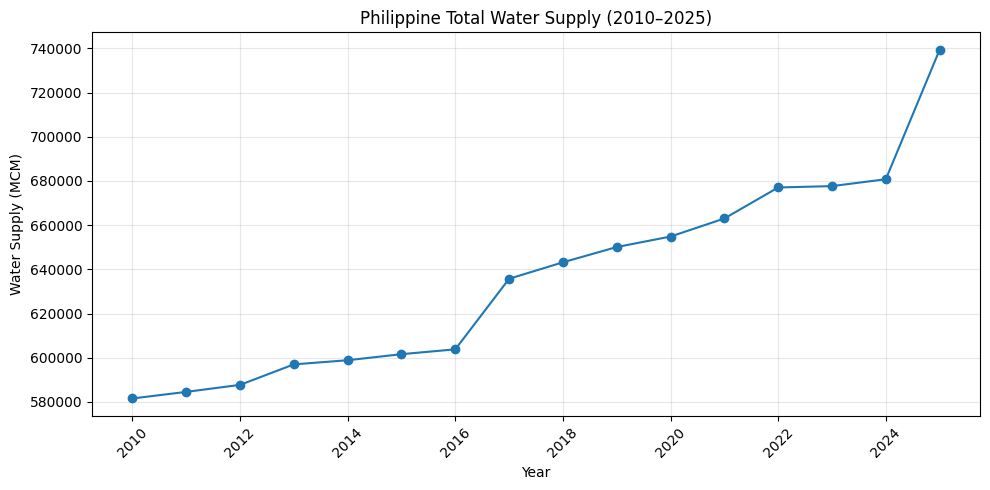

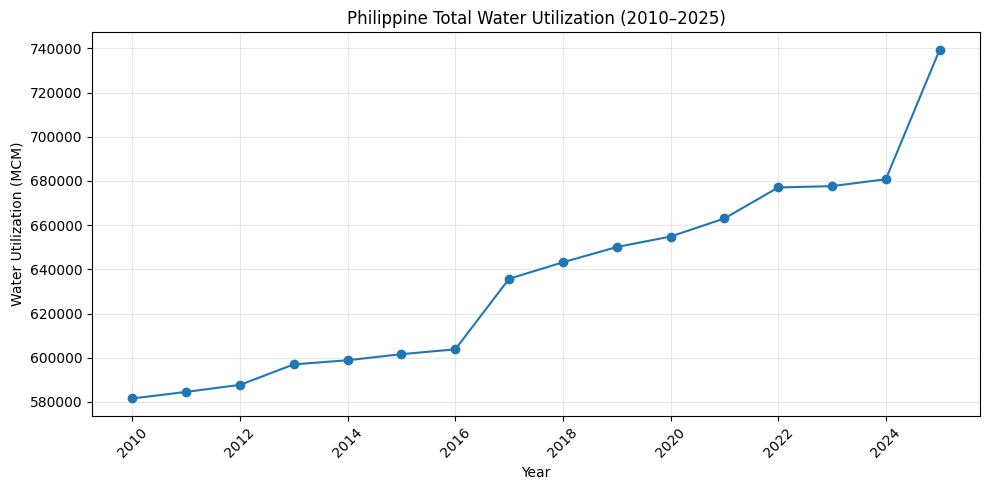

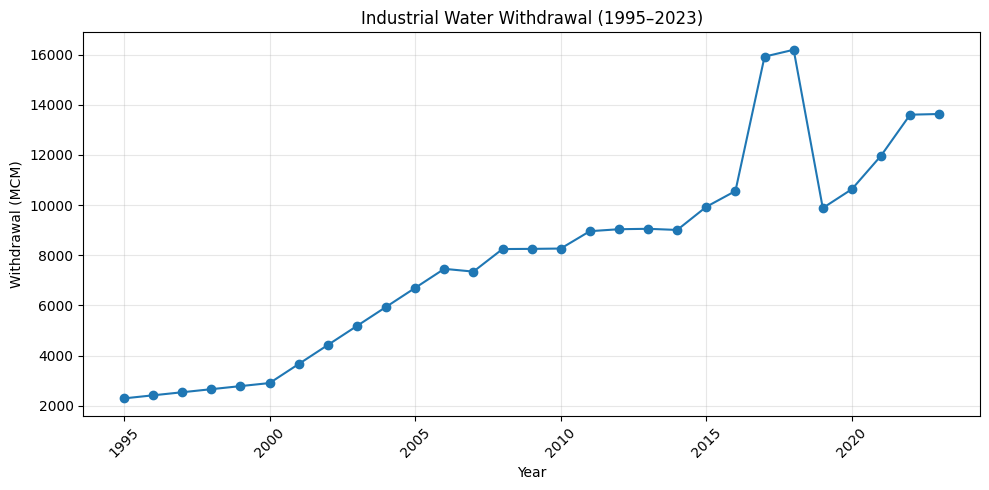

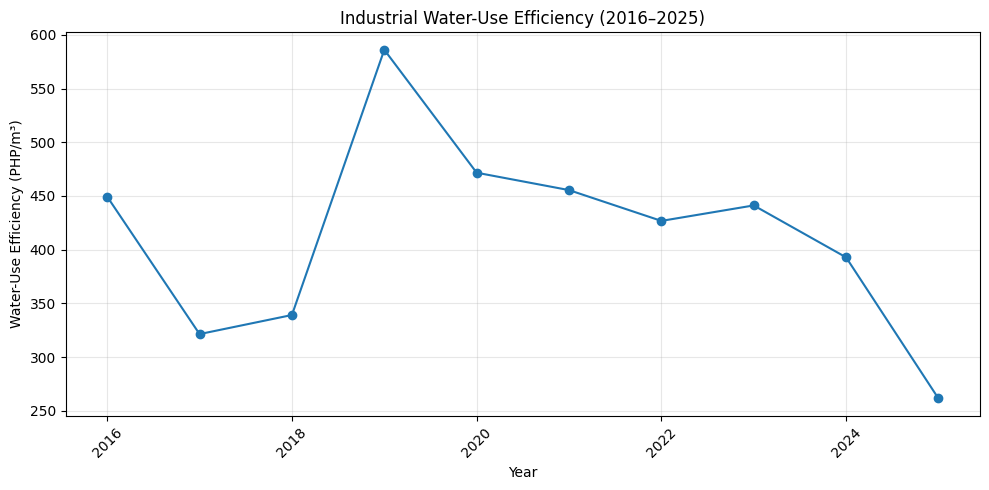

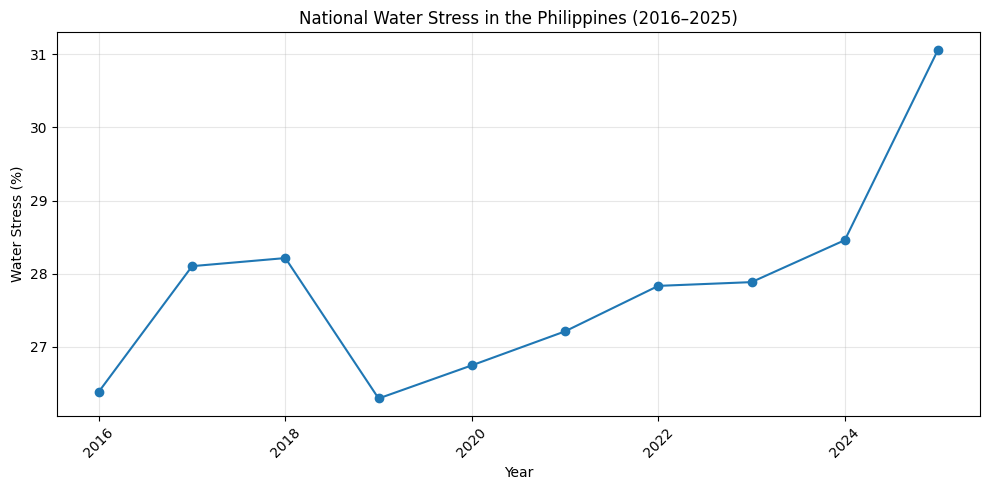

In [8]:

# ============================================
# TREND ANALYSIS AND CORRELATION ANALYSIS
# Philippine Water Resources Study
# ============================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import io
from google.colab import files


# ============================================
# 1. UPLOAD DATASETS
# ============================================

uploaded = files.upload()

def find_uploaded_file(base_name):
    for filename in uploaded.keys():
        if filename.startswith(base_name):
            return pd.read_csv(io.BytesIO(uploaded[filename]))

    raise FileNotFoundError(
        f"{base_name} was not uploaded. Please try again."
    )

annual_df = find_uploaded_file("annual_master_dataset")
common_df = find_uploaded_file("common_period_dataset")

print("Both datasets uploaded successfully!")

print("\nAnnual Master Dataset:")
display(annual_df.head())

print("\nCommon Period Dataset:")
display(common_df.head())

# ============================================
# 2. PREPARE TREND DATA
# ============================================

annual_df["year"] = pd.to_numeric(
    annual_df["year"], errors="coerce"
)

annual_df = annual_df.sort_values("year")

# Function for creating individual trend charts
def plot_trend(data, column, title, ylabel):

    plot_data = data[["year", column]].dropna()

    plt.figure(figsize=(10, 5))

    plt.plot(
        plot_data["year"],
        plot_data[column],
        marker="o"
    )

    plt.title(title)
    plt.xlabel("Year")
    plt.ylabel(ylabel)
    plt.grid(alpha=0.3)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

# ============================================
# 3. WATER SUPPLY AND UTILIZATION
# ============================================

plot_trend(
    annual_df,
    "total_supply",
    "Philippine Total Water Supply (2010–2025)",
    "Water Supply (MCM)"
)

plot_trend(
    annual_df,
    "total_use",
    "Philippine Total Water Utilization (2010–2025)",
    "Water Utilization (MCM)"
)

# ============================================
# 4. INDUSTRIAL WATER WITHDRAWAL
# ============================================

plot_trend(
    annual_df,
    "owid_industrial_withdrawal_mcm",
    "Industrial Water Withdrawal (1995–2023)",
    "Withdrawal (MCM)"
)

# ============================================
# 5. INDUSTRIAL WATER-USE EFFICIENCY
# ============================================

plot_trend(
    annual_df,
    "wue_industry",
    "Industrial Water-Use Efficiency (2016–2025)",
    "Water-Use Efficiency (PHP/m³)"
)


# ============================================
# 6. NATIONAL WATER STRESS
# ============================================

stress_df = annual_df[["year", "water_stress"]].dropna()

plt.figure(figsize=(10, 5))

plt.plot(
    stress_df["year"],
    stress_df["water_stress"] * 100,
    marker="o"
)

plt.title("National Water Stress in the Philippines (2016–2025)")
plt.xlabel("Year")
plt.ylabel("Water Stress (%)")
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



**INTERPRETATION:**

1. The trend analysis shows that Philippine total water supply generally increased from 2010 to 2025. The recorded value rose from approximately 581,572 MCM in 2010 to 739,393 MCM in 2025. Although the trend was generally increasing, some periods showed more noticeable changes than others. This indicates changes in the recorded national water supply over the observation period.

2. The trend analysis of Philippine total water utilization showed an increasing pattern from 2010 to 2025. However, the prepared dataset contained identical annual values for total water supply and total water utilization. Therefore, these two indicators should not be interpreted as independent measurements until their accounting definitions and preparation procedures are verified.

3. The trend analysis indicates that industrial water withdrawal in the Philippines generally increased from 1995 to 2023, although fluctuations were observed throughout the period. A particularly noticeable increase occurred in 2017 and 2018, followed by a decline in 2019. Withdrawal increased again in the succeeding years, reaching approximately 13,600 MCM in 2022 and 2023. These changes demonstrate variations in industrial water demand over time.

4. The industrial water-use efficiency trend showed considerable fluctuations from 2016 to 2025. The highest value was recorded in 2019 at approximately 586.11 PHP/m³, while the lowest occurred in 2025 at approximately 261.47 PHP/m³. After reaching its peak in 2019, industrial water-use efficiency generally declined, with minor increases in some years. This suggests variations in the economic value generated relative to the volume of water used by the industrial sector.

5. The national water stress trend showed fluctuations from 2016 to 2025, with an overall increase toward the end of the observation period. Water stress reached its lowest level in 2019 at approximately 26.29% and its highest level in 2025 at approximately 31.06%. The increase in the final years suggests a growing level of pressure on available freshwater resources at the national level.

**Correlation Analysis - Correlations across the Eight Overlapping Years (2016-2023)**

CORRELATION MATRIX


,total_supply,total_use,owid_industrial_withdrawal_mcm,water_used_industry,wue_industry,wue_overall,water_withdrawal_mcm,water_stress
total_supply,1.000,1.000,0.143,0.136,0.145,0.800,0.387,0.387
total_use,1.000,1.000,0.143,0.136,0.145,0.800,0.387,0.387
owid_industrial_withdrawal_mcm,0.143,0.143,1.000,1.000,-0.896,-0.192,0.961,0.961
water_used_industry,0.136,0.136,1.000,1.000,-0.898,-0.198,0.960,0.960
wue_industry,0.145,0.145,-0.896,-0.898,1.000,0.555,-0.821,-0.821
wue_overall,0.800,0.800,-0.192,-0.198,0.555,1.000,0.008,0.008
water_withdrawal_mcm,0.387,0.387,0.961,0.960,-0.821,0.008,1.000,1.000
water_stress,0.387,0.387,0.961,0.960,-0.821,0.008,1.000,1.000


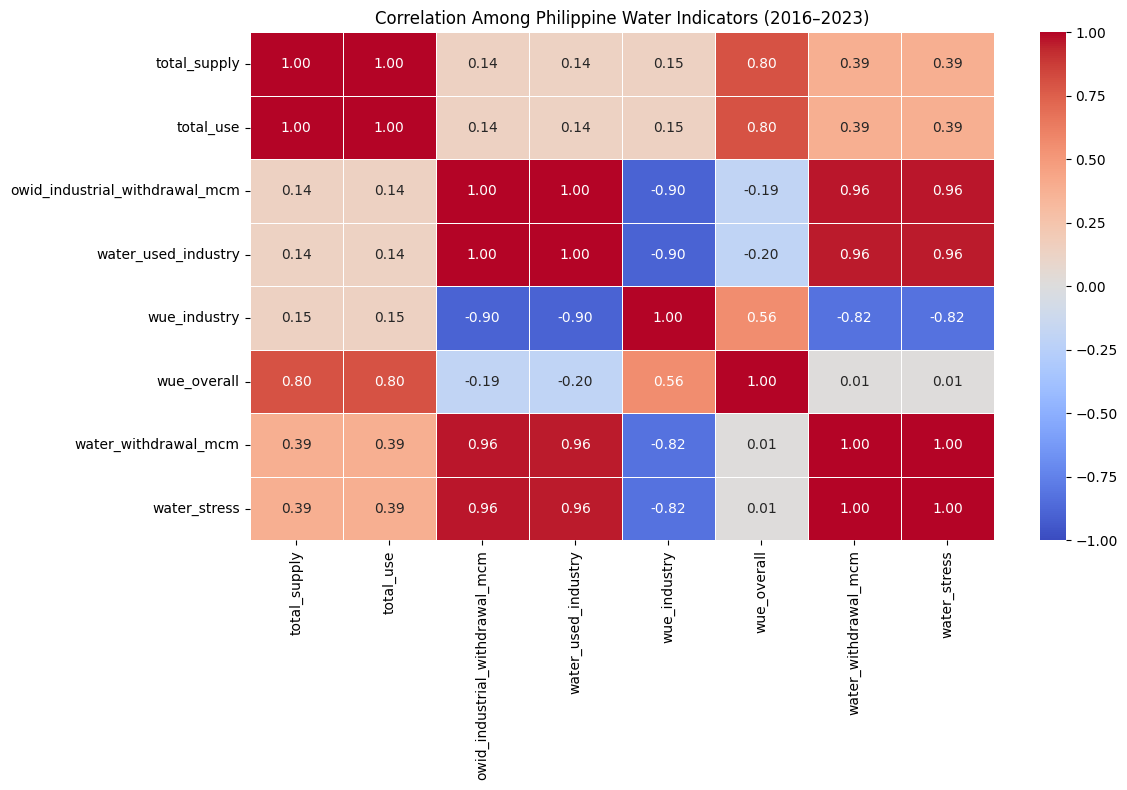

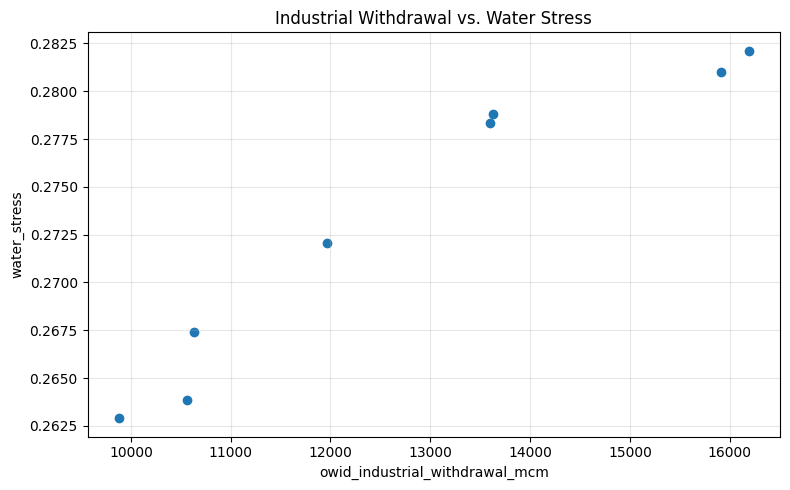

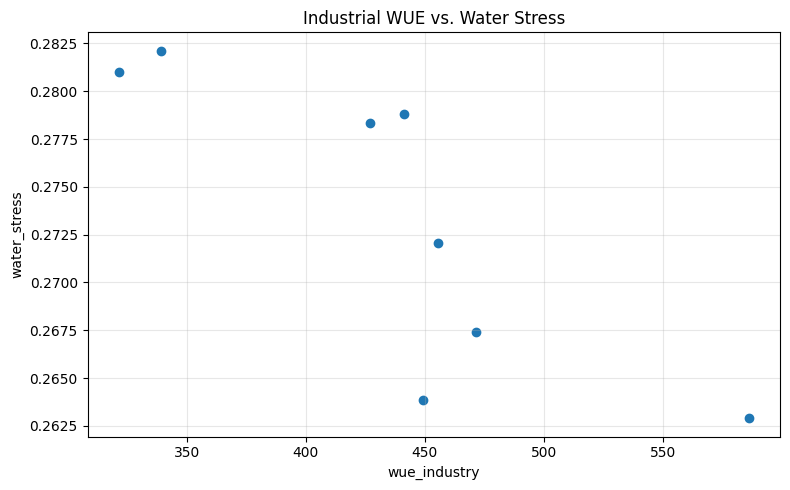

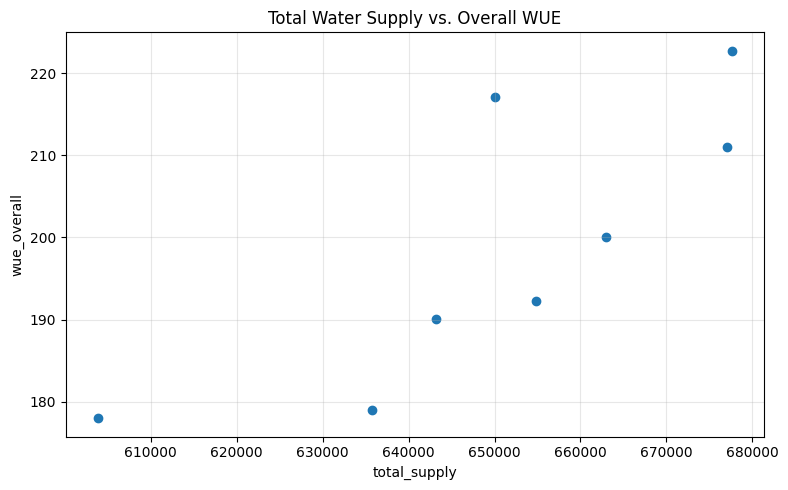


Correlation Analysis completed!


In [6]:

# ============================================
# 7. CORRELATION ANALYSIS
# ============================================

# Select numerical indicators
correlation_columns = [
    "total_supply",
    "total_use",
    "owid_industrial_withdrawal_mcm",
    "water_used_industry",
    "wue_industry",
    "wue_overall",
    "water_withdrawal_mcm",
    "water_stress"
]

correlation_data = common_df[
    correlation_columns
].apply(pd.to_numeric, errors="coerce")

# Calculate Pearson correlation
correlation_matrix = correlation_data.corr(
    method="pearson"
)

print("CORRELATION MATRIX")
display(correlation_matrix.round(3))

# ============================================
# 8. CORRELATION HEATMAP
# ============================================

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    center=0,
    vmin=-1,
    vmax=1
)

plt.title(
    "Correlation Among Philippine Water Indicators (2016–2023)"
)

plt.tight_layout()
plt.show()

# ============================================
# 9. SELECTED SCATTER PLOTS
# ============================================

selected_pairs = [
    (
        "owid_industrial_withdrawal_mcm",
        "water_stress",
        "Industrial Withdrawal vs. Water Stress"
    ),
    (
        "wue_industry",
        "water_stress",
        "Industrial WUE vs. Water Stress"
    ),
    (
        "total_supply",
        "wue_overall",
        "Total Water Supply vs. Overall WUE"
    )
]

for x, y, title in selected_pairs:

    plot_data = correlation_data[[x, y]].dropna()

    plt.figure(figsize=(8, 5))

    plt.scatter(
        plot_data[x],
        plot_data[y]
    )

    plt.title(title)
    plt.xlabel(x)
    plt.ylabel(y)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

print("\nCorrelation Analysis completed!")


INTERPRETATION:

1. Positive relationships - Industrial water withdrawal and national water stress have a very strong positive correlation of +0.961. This means that higher industrial withdrawal values tended to occur alongside higher national water stress values during the overlapping observation period.
2. Negative relationships - Industrial water-use efficiency and national water stress have a strong negative correlation of −0.821. This suggests that higher industrial water-use efficiency values tended to coincide with lower water stress values in the observed years.
3. Strongest and weakest relationships - The strongest positive correlation is between total water supply and total water utilization at +1.000. However, these columns are identical in the prepared dataset, so this is not an independent finding. The weakest relationship is between overall water-use efficiency and national water stress at +0.008, indicating almost no linear relationship in the eight observations.
4. Industrial withdrawal and national water stress - The strong positive correlation of +0.961 suggests that industrial water withdrawal and national water stress moved in the same direction during the observation period. However, water withdrawal is part of the calculation of the national water stress indicator. Therefore, this relationship is partly expected from the indicator's construction and should not be interpreted as proof that industrial withdrawal independently caused increased national water stress.
5. Implications for Philippine water-resource management - The findings suggest that industrial water demand and industrial water-use efficiency are relevant indicators to consider when examining national water-resource conditions. Monitoring industrial water use and encouraging efficient water practices may support sustainable water-resource management. However, the correlations alone cannot establish the effects of industrial activities on national water stress.